<a href="https://colab.research.google.com/github/sandhya156/TB-Prediction-System/blob/main/sputum_tb_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#drive mount cell1
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#unzip cell2
import glob
zip_path = glob.glob('/content/drive/MyDrive/tb_sputum/*.zip')[0]
print("Zip mili:", zip_path)
!unzip -q "{zip_path}" -d /content/sputum_raw
print("Unzip done ✅")

Zip mili: /content/drive/MyDrive/tb_sputum/AI-TB-ZN_Image_Dataset_v1.0.zip.zip
Unzip done ✅


In [3]:
#import+path cell 3
import os, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import load_img
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

pos_dir = '/content/sputum_raw/TB IMAGES DATA SET/TBPOSITIVE'
neg_dir = '/content/sputum_raw/TB IMAGES DATA SET/TBNEGATIVE'
exts = ('.jpg', '.jpeg', '.png')

print("Paths:", os.path.exists(pos_dir), os.path.exists(neg_dir))
print("GPU:", tf.config.list_physical_devices('GPU'))

Paths: True True
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


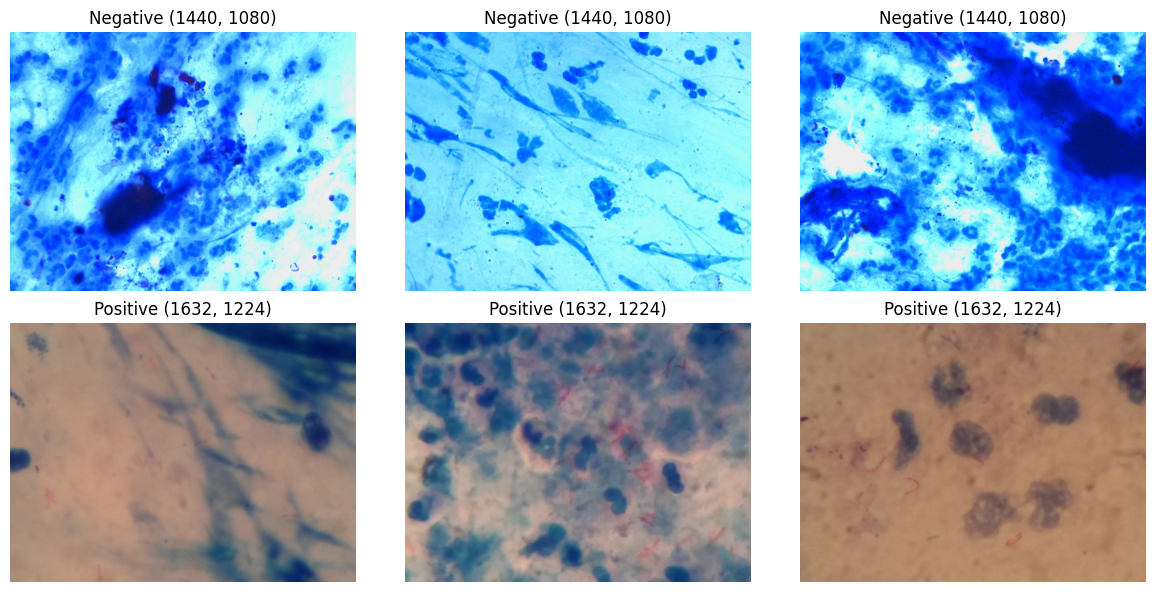

In [4]:
plt.figure(figsize=(12, 6)) #cell 4
i = 1
for name, d in [('Negative', neg_dir), ('Positive', pos_dir)]:
    files = [f for f in os.listdir(d) if f.lower().endswith(exts)]
    for f in random.sample(files, 3):
        img = load_img(os.path.join(d, f))
        plt.subplot(2, 3, i)
        plt.imshow(img)
        plt.title(f"{name} {img.size}")
        plt.axis('off')
        i += 1
plt.tight_layout()
plt.show()

In [ ]:
#train/val/test split cell 5
IMG = (224, 224)
BATCH = 32

paths, labels = [], []
for label, d in [(0, neg_dir), (1, pos_dir)]:
    for f in os.listdir(d):
        if f.lower().endswith(exts):
            paths.append(os.path.join(d, f))
            labels.append(label)
paths, labels = np.array(paths), np.array(labels)

train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=42)

print("Train:", len(train_p), "| Val:", len(val_p), "| Test:", len(test_p))
print("Positive in train/val/test:", train_y.sum(), val_y.sum(), test_y.sum())

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG)
    img.set_shape((IMG[0], IMG[1], 3))
    return img, tf.cast(label, tf.float32)

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=42)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_p, train_y, shuffle=True)
val_ds   = make_ds(val_p, val_y)
test_ds  = make_ds(test_p, test_y)

Train: 358 | Val: 77 | Test: 77
Positive in train/val/test: 179 39 38


In [ ]:
#model cell 6
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    layers.Input((224, 224, 3)),
    aug,
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.Precision(name='precision')])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#train cell 7
os.makedirs('/content/drive/MyDrive/tb_sputum/models', exist_ok=True)

cb = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/tb_sputum/models/sputum_model.keras',
        monitor='val_loss', save_best_only=True)
]

history = model.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=cb)

Epoch 1/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 520ms/step - accuracy: 0.6676 - loss: 0.6195 - precision: 0.6899 - recall: 0.6089 - val_accuracy: 0.7143 - val_loss: 0.4794 - val_precision: 0.7179 - val_recall: 0.7179
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 271ms/step - accuracy: 0.7179 - loss: 0.5084 - precision: 0.7143 - recall: 0.7263 - val_accuracy: 0.7922 - val_loss: 0.4126 - val_precision: 0.7805 - val_recall: 0.8205
Epoch 3/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 283ms/step - accuracy: 0.7877 - loss: 0.4459 - precision: 0.8084 - recall: 0.7542 - val_accuracy: 0.8312 - val_loss: 0.3656 - val_precision: 0.8421 - val_recall: 0.8205
Epoch 4/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 413ms/step - accuracy: 0.7821 - loss: 0.4209 - precision: 0.8098 - recall: 0.7374 - val_accuracy: 0.8442 - val_loss: 0.3432 - val_precision: 0.8649 - val_recall: 0.8205
Epoch 5/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - accuracy: 0.8017 - loss: 0.3882 - precision: 0.8293 - recall: 0.7598 - val_accuracy: 0.8571 - val_loss: 0

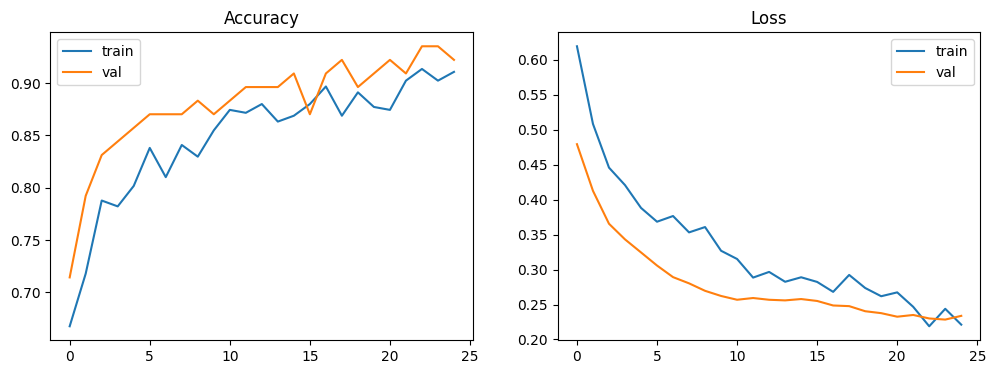

In [ ]:
#Training curves cell 8
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss'); plt.legend()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87        39
    Positive       0.87      0.87      0.87        38

    accuracy                           0.87        77
   macro avg       0.87      0.87      0.87        77
weighted avg       0.87      0.87      0.87        77



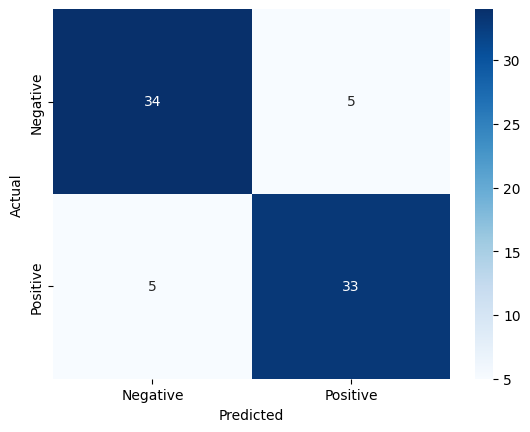

In [ ]:
#Test pe evaluation cell 9
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(test_y, y_pred, target_names=['Negative', 'Positive']))

cm = confusion_matrix(test_y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

In [ ]:
#Fusion ke liye prediction function cell10
def predict_sputum(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img)[None, ...]
    return float(model.predict(arr, verbose=0)[0][0])   # TB probability (0 to 1)

# test
print(predict_sputum(test_p[0]), "| actual:", test_y[0])

0.9904654026031494 | actual: 1


In [ ]:
#cell11 Fine-tuning (MobileNetV2 ki last layers unfreeze)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.Precision(name='precision')])

cb_ft = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/tb_sputum/models/sputum_model_finetuned.keras',
        monitor='val_loss', save_best_only=True)
]

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb_ft)

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 538ms/step - accuracy: 0.8911 - loss: 0.2452 - precision: 0.8804 - recall: 0.9050 - val_accuracy: 0.8831 - val_loss: 0.2226 - val_precision: 0.9167 - val_recall: 0.8462
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 233ms/step - accuracy: 0.9022 - loss: 0.2276 - precision: 0.9444 - recall: 0.8547 - val_accuracy: 0.9351 - val_loss: 0.2298 - val_precision: 0.9250 - val_recall: 0.9487
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 325ms/step - accuracy: 0.8994 - loss: 0.1978 - precision: 0.8950 - recall: 0.9050 - val_accuracy: 0.8831 - val_loss: 0.2352 - val_precision: 0.9167 - val_recall: 0.8462
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - accuracy: 0.9218 - loss: 0.1990 - precision: 0.9364 - recall: 0.9050 - val_accuracy: 0.9351 - val_loss: 0.2150 - val_precision: 0.9250 - val_recall: 0.9487
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 345ms/step - accuracy: 0.9190 - loss: 0.1913 - precision: 0.9121 - recall: 0.9274 - val_accuracy: 0.9351 - val_loss: 0

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step
              precision    recall  f1-score   support

    Negative       0.95      0.95      0.95        39
    Positive       0.95      0.95      0.95        38

    accuracy                           0.95        77
   macro avg       0.95      0.95      0.95        77
weighted avg       0.95      0.95      0.95        77



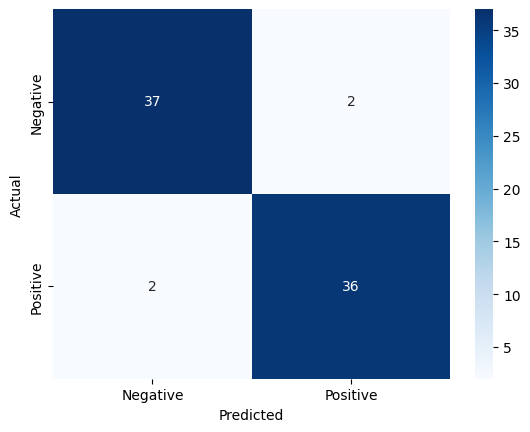

In [ ]:
#Test pe evaluation cell 9 12
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(test_y, y_pred, target_names=['Negative', 'Positive']))

cm = confusion_matrix(test_y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

In [ ]:
#Cell 13: Best saved model load karke confirm karo
best = tf.keras.models.load_model(
    '/content/drive/MyDrive/tb_sputum/models/sputum_model_finetuned.keras')

y_prob = best.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)
print(classification_report(test_y, y_pred, target_names=['Negative', 'Positive']))
print(confusion_matrix(test_y, y_pred))

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 998ms/step
              precision    recall  f1-score   support

    Negative       0.95      0.95      0.95        39
    Positive       0.95      0.95      0.95        38

    accuracy                           0.95        77
   macro avg       0.95      0.95      0.95        77
weighted avg       0.95      0.95      0.95        77

[[37  2]
 [ 2 36]]


In [ ]:
#Cell 14: Fusion function (best model ke saath)
def predict_sputum(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img)[None, ...]
    return float(best.predict(arr, verbose=0)[0][0])   # TB probability (0 to 1)

print(predict_sputum(test_p[0]), "| actual:", test_y[0])

0.9994537234306335 | actual: 1
